# Leiden clustering cells by expression and visualizing with UMAP

Creating a neighborhood graph using the X_pca data we created. (X_pca stores the locations of each cell along each pc)

In [14]:
import scanpy as sc
adata = sc.read_h5ad("data/processed_pbmc.h5ad")

Make neighborhood map for Leiden clustering

In [15]:
# cells that have similar expression should be near each other in a graph 
# we're going with 10 pcs to use some of the info the later pcs give too
# n_neighbors means find the 10 most similar cells for each cell, not all cells are shown
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10) 
adata.obsp.keys() # obsp means observation pair, how pairs of cells relate to each other 


KeysView(PairwiseArrays with keys: distances, connectivities)

UMAP to visualize

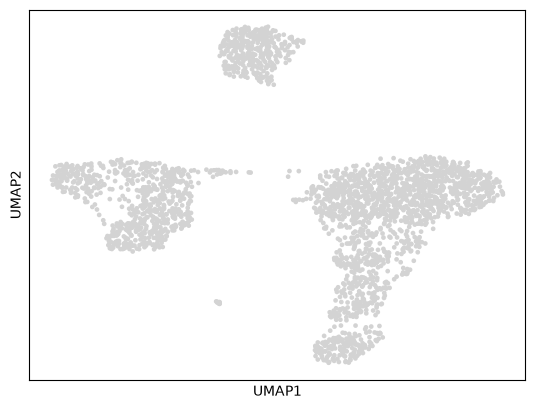

In [16]:
# UMAP 
sc.tl.umap(adata)
sc.pl.umap(adata)

In [17]:
sc.tl.leiden(adata)
adata.obs.head()

,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,leiden
index,,,,,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226,75.0,4.330733,3.097893,4
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884,190.0,5.252274,3.875179,0
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893,34.0,3.555348,1.079708,7
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155,52.0,3.970292,1.970443,5
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390,14.0,2.708050,1.427115,8


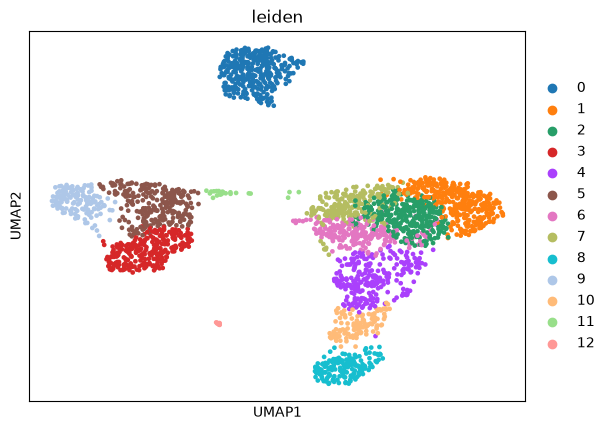

In [18]:
sc.pl.umap(
    adata, 
    color="leiden"
)

This is what the clusters look like after leiden clustering. Let's see which genes are most informative for each cluster. 

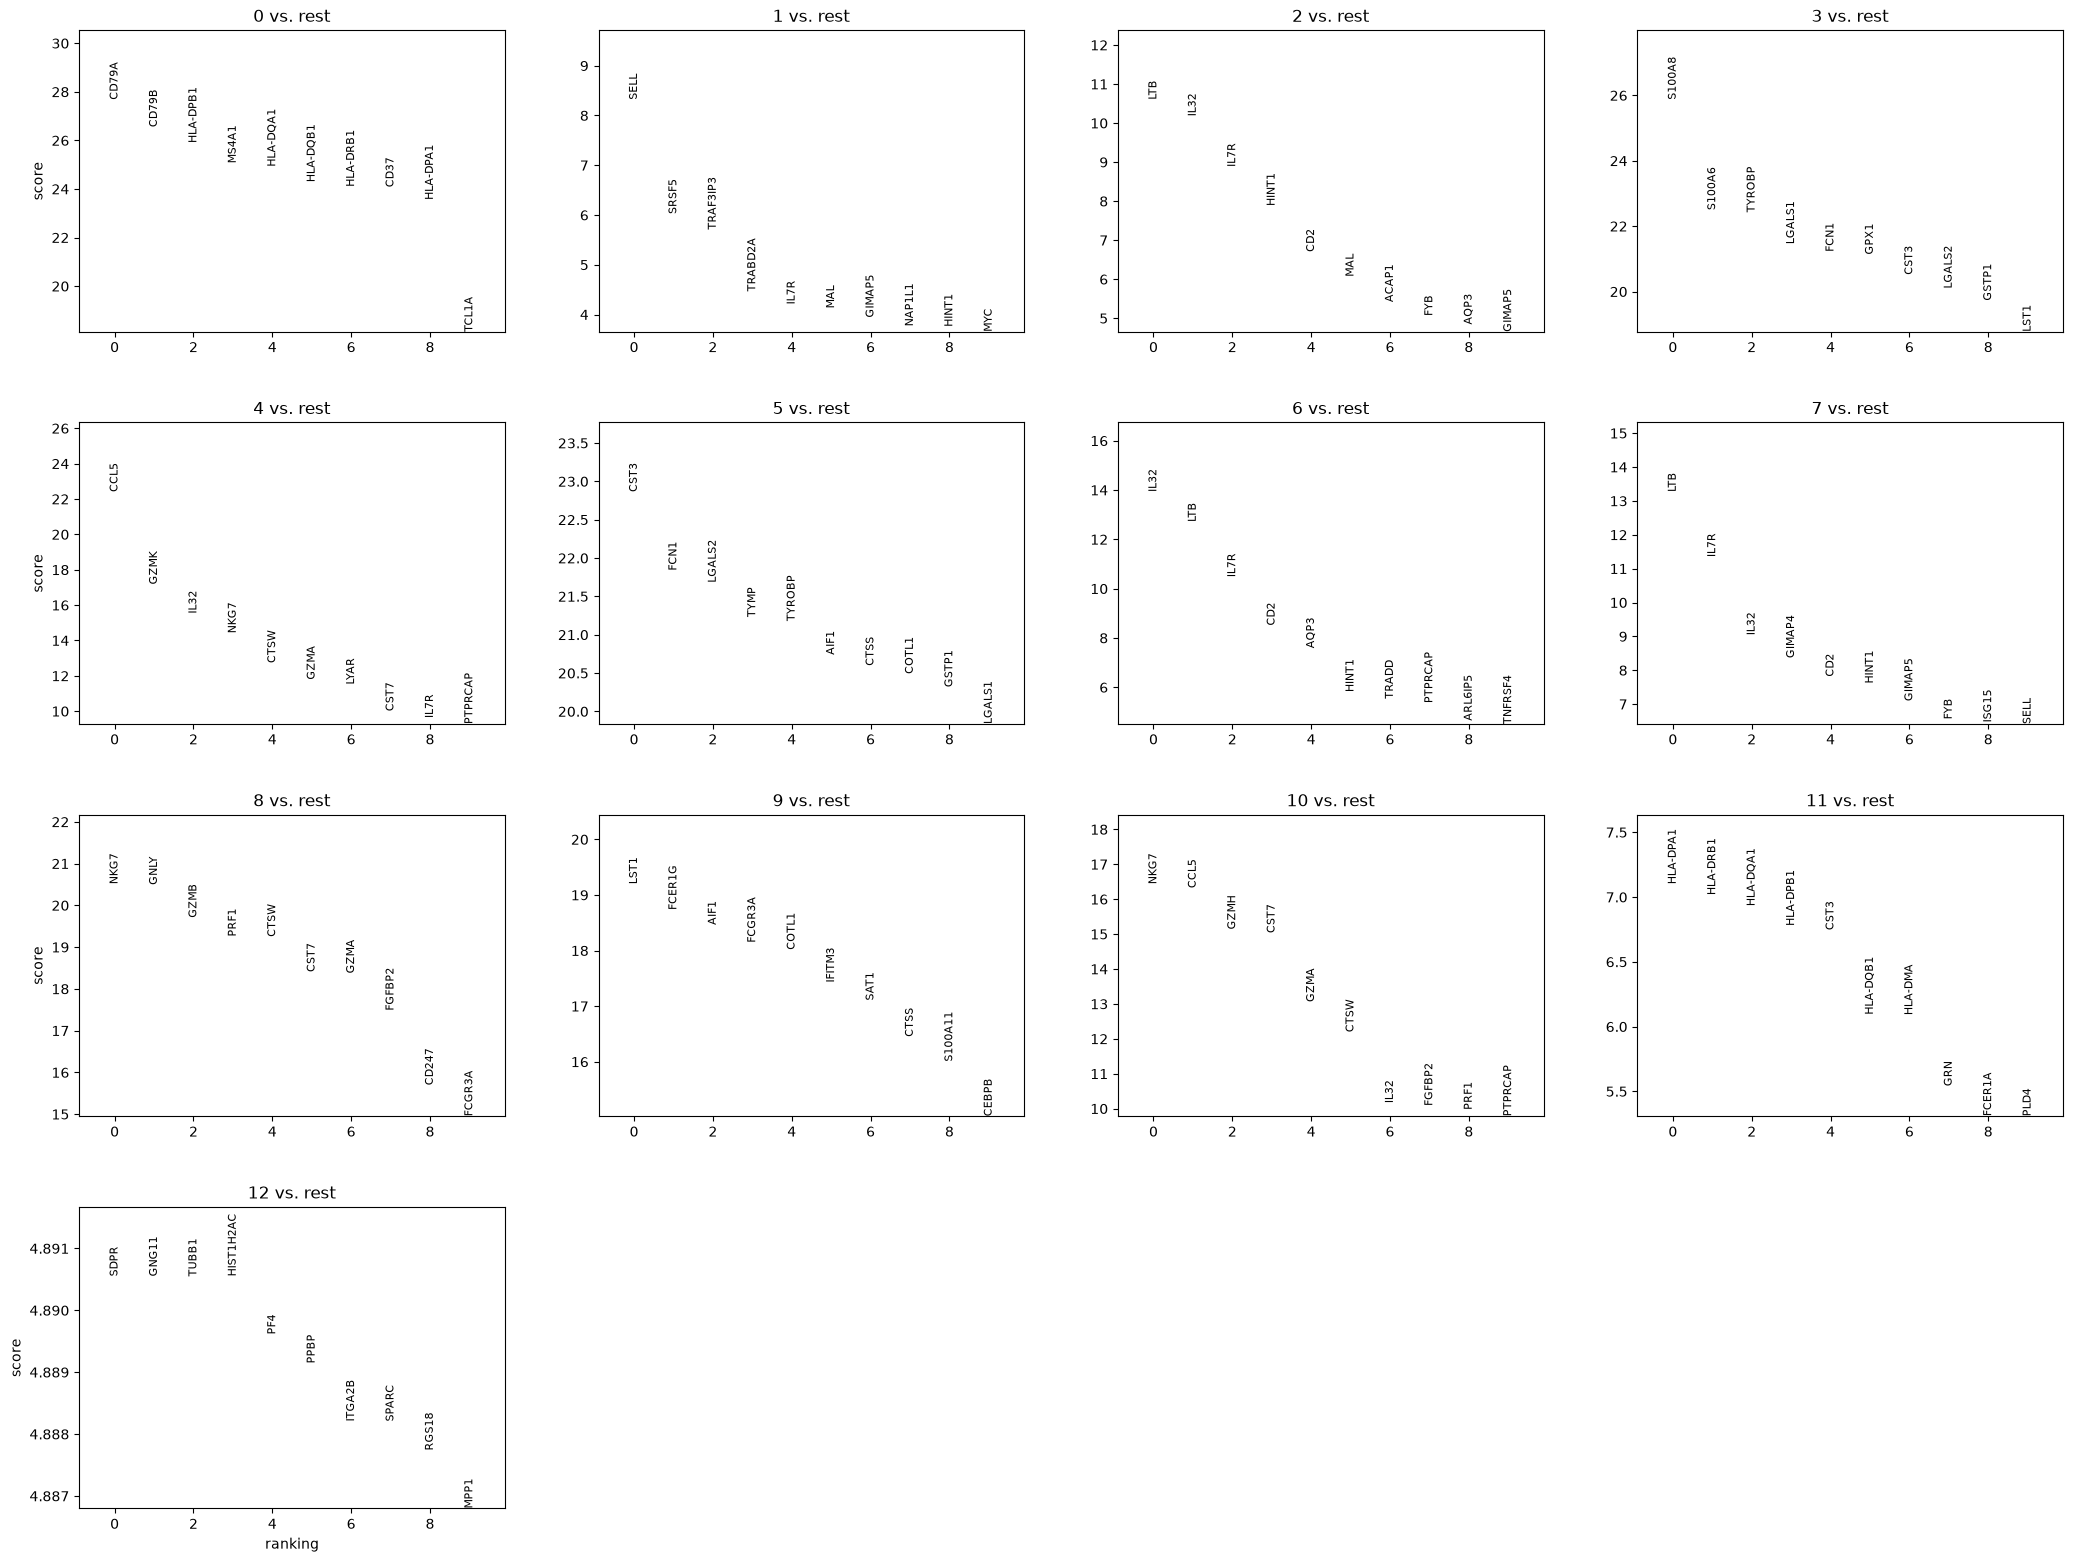

In [19]:
# this will tell us for each cluster which gene is highest expressed
sc.tl.rank_genes_groups(
    adata, 
    groupby="leiden", 
    method="wilcoxon"
)
sc.pl.rank_genes_groups(
    adata, 
    n_genes=10, 
    sharey=False
)

In [20]:
result = sc.get.rank_genes_groups_df(
    adata, 
    group=None
)
result.head()

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
2,0,HLA-DPB1,25.892418,4.072172,8.106834e-148,5.369426e-145
3,0,MS4A1,25.057699,6.423985,1.439133e-138,7.148895e-136
4,0,HLA-DQA1,24.917364,5.313763,4.824401e-137,1.917217e-134


In [21]:
top5 = (
    result
    .sort_values(["group", "scores"], ascending=[True, False]) # sort group in ascending order FIRST then scores in descending SECOND
    .groupby("group") # "groups" each cluster
    .head(2) # shows top 2 genes for each group
)
top5


/var/folders/gv/gbf3xv4d3hl0xccvbw6j48_m0000gn/T/ipykernel_22509/3922084279.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group") # "groups" each cluster


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
1987,1,SELL,8.316856,1.169984,9.032714e-17,8.158184e-15
1988,1,SRSF5,6.020982,0.620136,1.733623e-09,9.310023e-08
3974,2,LTB,10.598515,1.594969,3.027500e-26,1.503911e-23
3975,2,IL32,10.173858,1.634788,2.594248e-24,7.363957e-22
5961,3,S100A8,25.866749,7.151405,1.576831e-147,3.133164e-144
5962,3,S100A6,22.491323,2.835183,5.047189e-112,5.014383e-109
7948,4,CCL5,22.399811,5.324578,3.952490e-111,7.853598e-108
7949,4,GZMK,17.170605,5.657723,4.407997e-66,4.379345e-63


In [22]:
top5[["group", "names"]] # pulls a subset of the df with cols group and names

,group,names
0,0,CD79A
1,0,CD79B
1987,1,SELL
1988,1,SRSF5
3974,2,LTB
3975,2,IL32
5961,3,S100A8
5962,3,S100A6
7948,4,CCL5
7949,4,GZMK


In [23]:
characteristic_genes = {}
for i in range(13):
    genes = top5[top5["group"] == str(i)]["names"].tolist()
    characteristic_genes[i] = genes

print(characteristic_genes)

{0: ['CD79A', 'CD79B'], 1: ['SELL', 'SRSF5'], 2: ['LTB', 'IL32'], 3: ['S100A8', 'S100A6'], 4: ['CCL5', 'GZMK'], 5: ['CST3', 'FCN1'], 6: ['IL32', 'LTB'], 7: ['LTB', 'IL7R'], 8: ['NKG7', 'GNLY'], 9: ['LST1', 'FCER1G'], 10: ['NKG7', 'CCL5'], 11: ['HLA-DPA1', 'HLA-DRB1'], 12: ['SDPR', 'GNG11']}


Now we know which genes are most informative for each cluster, but we have no biological interpretation. We have to manually map which cell types express these genes shown, and make a dictionary to map cluster to cell type. 

In [24]:
cluster_to_celltype = {
    "0": "B cell",
    "1": "T cell",
    "2": "T cell",
    "3": "Classical monocyte",
    "4": "Memory/effector T cell",
    "5": "Classical monocyte",
    "6": "T cell",
    "7": "T cell",
    "8": "NK cell",
    "9": "FCGR3A+ monocyte",
    "10": "NK/cytotoxic lymphocyte",
    "11": "Dendritic/APC",
    "12": "Megakaryocyte",
}
# map the cluster numbers to the new labels
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_celltype)
adata.obs[["leiden", "cell_type"]].head(20)

,leiden,cell_type
index,,
AAACATACAACCAC-1,4,Memory/effector T cell
AAACATTGAGCTAC-1,0,B cell
AAACATTGATCAGC-1,7,T cell
AAACCGTGCTTCCG-1,5,Classical monocyte
AAACCGTGTATGCG-1,8,NK cell
AAACGCACTGGTAC-1,2,T cell
AAACGCTGACCAGT-1,4,Memory/effector T cell
AAACGCTGGTTCTT-1,4,Memory/effector T cell
AAACGCTGTAGCCA-1,4,Memory/effector T cell


In [25]:
# for each cell type, count how many cells there are
adata.obs["cell_type"].value_counts()

cell_type
T cell                     1075
Classical monocyte          509
B cell                      338
Memory/effector T cell      247
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                23
Megakaryocyte                 8
Name: count, dtype: int64

In [26]:
adata.write("data/annotated_pbmc.h5ad")